# Fake News Detection (PhoBERT) - Đánh giá, Thuật toán Tìm kiếm/Tối ưu & Thử nghiệm
Chạy trên Google Colab (bật GPU T4). Chạy lần lượt từng ô. Kết quả lưu trong thư mục `results/`.

Yêu cầu dữ liệu: 3 file `train.csv`, `val.csv`, `test.csv` có cột `text` và `label` (1 = tin giả, 0 = tin thật), do thành viên phụ trách dữ liệu cung cấp.

In [8]:
!pip -q install transformers datasets optuna scikit-learn pandas matplotlib seaborn pyvi accelerate

In [9]:
import os, time, json, random, itertools, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoConfig,
                          TrainingArguments, Trainer, DataCollatorWithPadding, TrainerCallback)
import optuna
from pyvi import ViTokenizer
warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)

## 0. Cấu hình

In [10]:
DATA_DIR = "."                      # thư mục chứa train.csv, val.csv, test.csv
MODEL_NAME = "vinai/phobert-base"
SEEDS = [42, 123, 2024]
N_TRIALS = 12                       # NGÂN SÁCH chung cho mỗi thuật toán tìm kiếm (tăng nếu đủ thời gian GPU)
SEARCH_TRAIN_FRAC = 0.3             # dùng 30% tập train khi tìm kiếm để tiết kiệm thời gian; huấn luyện cuối dùng 100%
DEFAULTS = dict(lr=2e-5, bs=16, epochs=3, dropout=0.1, wd=0.01, warmup=0.1, max_len=256)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

## 1. Dữ liệu

In [11]:
train = pd.read_csv(f"{DATA_DIR}/train.csv", encoding="utf-8-sig"); val = pd.read_csv(f"{DATA_DIR}/val.csv", encoding="utf-8-sig"); test = pd.read_csv(f"{DATA_DIR}/test.csv", encoding="utf-8-sig")
for d in (train, val, test):
    d["text"] = d["text"].astype(str)
print(train.shape, val.shape, test.shape)
print(train["label"].value_counts(normalize=True))

# PhoBERT cần văn bản đã tách từ. Nếu thành viên dữ liệu đã tách từ sẵn (từ ghép nối bằng "_"), đặt ALREADY_SEGMENTED=True.
ALREADY_SEGMENTED = True   # dữ liệu nhóm đưa đã tách từ sẵn (từ ghép nối bằng "_")
def seg(t): return t if ALREADY_SEGMENTED else ViTokenizer.tokenize(t)
for d in (train, val, test):
    d["text_seg"] = d["text"].map(seg)
    d["text_raw"] = d["text_seg"].str.replace("_", " ", regex=False)   # bản không tách từ (cho XLM-R và ablation A1)

search_train = train.groupby("label", group_keys=False).apply(
    lambda g: g.sample(frac=SEARCH_TRAIN_FRAC, random_state=0)).reset_index(drop=True)
print("search subset:", search_train.shape)

(3423, 2) (428, 2) (428, 2)
label
0    0.831434
1    0.168566
Name: proportion, dtype: float64
search subset: (1027, 4)


## 2. Hàm đánh giá chung

In [12]:
def compute_metrics_np(y, prob):
    pred = (prob >= 0.5).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", pos_label=1, zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision=p, recall=r, f1_fake=f,
                f1_macro=f1_score(y, pred, average="macro"),
                roc_auc=roc_auc_score(y, prob) if len(set(y)) > 1 else float("nan"))

## 3. Mô hình Transformer: huấn luyện + đánh giá (dùng cho baseline, tìm kiếm, ablation)

In [13]:
class DS(torch.utils.data.Dataset):
    def __init__(self, enc, labels): self.enc, self.labels = enc, labels
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}; item["labels"] = int(self.labels[i]); return item

class WeightedTrainer(Trainer):
    cw = None
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels"); out = model(**inputs)
        loss = nn.CrossEntropyLoss(weight=self.cw.to(out.logits.device))(out.logits, labels)
        return (loss, out) if return_outputs else loss

class PruneCB(TrainerCallback):
    def __init__(self, trial, y_val): self.trial, self.y_val, self.trainer = trial, y_val, None
    def on_evaluate(self, args, state, control, metrics=None, **kw):
        f = metrics.get("eval_f1_macro")
        self.trial.report(f, step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()

def train_eval(params, seed=42, train_df=None, eval_df=None, text_col="text_seg",
               model_name=MODEL_NAME, class_weight=False, freeze_encoder=False, trial=None, return_probs=False):
    """Huấn luyện 1 cấu hình, trả về metrics trên eval_df (val khi tìm kiếm, test khi báo cáo cuối)."""
    p = {**DEFAULTS, **params}; set_seed(seed)
    train_df = train if train_df is None else train_df; eval_df = val if eval_df is None else eval_df
    tok = AutoTokenizer.from_pretrained(model_name)
    cfg = AutoConfig.from_pretrained(model_name, num_labels=2, classifier_dropout=p["dropout"])
    model = AutoModelForSequenceClassification.from_pretrained(model_name, config=cfg)
    if freeze_encoder:
        for n, prm in model.named_parameters():
            if not n.startswith("classifier"): prm.requires_grad = False
    enc = lambda df: tok(df[text_col].tolist(), truncation=True, max_length=int(p["max_len"]))
    dtr, dev = DS(enc(train_df), train_df["label"].values), DS(enc(eval_df), eval_df["label"].values)

    def cm(ep):
        logits, y = ep; prob = torch.softmax(torch.tensor(logits), -1)[:, 1].numpy()
        m = compute_metrics_np(y, prob); return {k: float(v) for k, v in m.items()}

    args = TrainingArguments(output_dir="tmp_out", per_device_train_batch_size=int(p["bs"]),
        per_device_eval_batch_size=64, learning_rate=p["lr"], num_train_epochs=int(p["epochs"]),
           weight_decay=p["wd"], warmup_steps=int(p["warmup"] * (-(-len(dtr) // int(p["bs"]))) * int(p["epochs"])),
   eval_strategy="epoch", save_strategy="no",
        logging_strategy="no", report_to="none", seed=seed, fp16=torch.cuda.is_available())
    TR = WeightedTrainer if class_weight else Trainer
    tr = TR(model=model, args=args, train_dataset=dtr, eval_dataset=dev, compute_metrics=cm,
            data_collator=DataCollatorWithPadding(tok),
            callbacks=[PruneCB(trial, eval_df["label"].values)] if trial is not None else [])
    if class_weight:
        cnt = np.bincount(train_df["label"].values); w = torch.tensor(len(train_df) / (2 * cnt), dtype=torch.float)
        tr.cw = w
    tr.train()
    out = tr.predict(dev); logits = out.predictions
    prob = torch.softmax(torch.tensor(logits), -1)[:, 1].numpy()
    m = compute_metrics_np(eval_df["label"].values, prob)
    del model, tr; torch.cuda.empty_cache()
    return (m, prob) if return_probs else m

## 4. Thuật toán tìm kiếm/tối ưu siêu tham số (cùng ngân sách N_TRIALS, hàm mục tiêu = F1 macro trên validation)

config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

...

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Fake,F1 Macro,Roc Auc
1,No log,0.424700,0.831776,0.000000,0.000000,0.000000,0.454082,0.822858
2,No log,0.352154,0.831776,0.000000,0.000000,0.000000,0.454082,0.882842
3,No log,0.323237,0.841121,0.750000,0.083333,0.150000,0.531186,0.888850


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Fake,F1 Macro,Roc Auc
1,No log,0.331070,0.831776,0.000000,0.000000,0.000000,0.454082,0.894799
2,No log,0.347516,0.859813,0.676471,0.319444,0.433962,0.676981,0.890937
3,No log,0.288963,0.887850,0.706897,0.569444,0.630769,0.782327,0.909078
4,No log,0.388389,0.892523,0.750000,0.541667,0.629032,0.783095,0.893083
5,No log,0.429188,0.880841,0.733333,0.458333,0.564103,0.747545,0.888986


Genetic Algorithm best F1 macro (val): 0.7574 {'bs': 32, 'dropout': 0.30543124850629855, 'epochs': 5, 'lr': 2.34344330957782e-05, 'max_len': 128, 'warmup': 0.1570670295633347, 'wd': 0.01844398656469153}


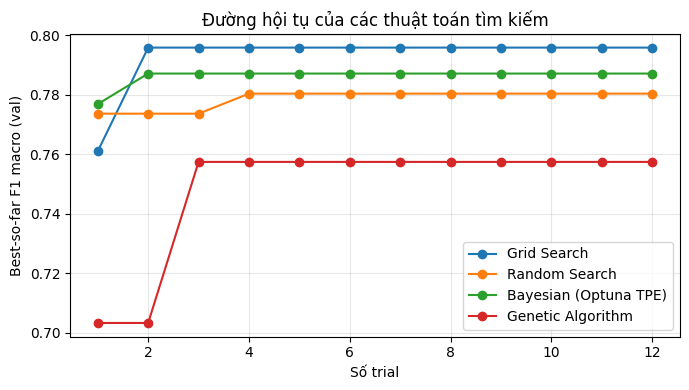

In [14]:
SPACE = dict(lr=(1e-5, 5e-5), bs=[16, 32], epochs=[3, 4, 5], dropout=(0.1, 0.5),
             wd=(0.0, 0.1), warmup=(0.0, 0.2), max_len=[128, 256])

def sample_random(rng):
    return dict(lr=float(np.exp(rng.uniform(np.log(SPACE["lr"][0]), np.log(SPACE["lr"][1])))),
                bs=int(rng.choice(SPACE["bs"])), epochs=int(rng.choice(SPACE["epochs"])),
                dropout=float(rng.uniform(*SPACE["dropout"])), wd=float(rng.uniform(*SPACE["wd"])),
                warmup=float(rng.uniform(*SPACE["warmup"])), max_len=int(rng.choice(SPACE["max_len"])))

def objective_fn(params, trial=None):
    return train_eval(params, seed=42, train_df=search_train, eval_df=val, trial=trial)["f1_macro"]

search_log = {}   # tên thuật toán -> dict(history=[...], best=..., params=..., minutes=...)

def finish(name, hist, params, t0):
    search_log[name] = dict(history=hist, best=float(max(hist)), params=params, trials=len(hist),
                            minutes=round((time.time() - t0) / 60, 1))
    print(name, "best F1 macro (val):", round(max(hist), 4), params)

# --- 4.1 Grid Search (lưới rời rạc nhỏ, cắt theo ngân sách) ---
t0 = time.time()
grid = [dict(lr=a, bs=b, epochs=3, dropout=d) for a, b, d in
        itertools.product([2e-5, 3e-5, 5e-5], [16, 32], [0.1, 0.3])]
random.Random(0).shuffle(grid); grid = grid[:N_TRIALS]
hist, best_p, best = [], None, -1
for g in grid:
    f = objective_fn(g); hist.append(f)
    if f > best: best, best_p = f, g
finish("Grid Search", hist, best_p, t0)

# --- 4.2 Random Search ---
t0 = time.time(); rng = np.random.RandomState(1); hist, best_p, best = [], None, -1
for _ in range(N_TRIALS):
    g = sample_random(rng); f = objective_fn(g); hist.append(f)
    if f > best: best, best_p = f, g
finish("Random Search", hist, best_p, t0)

# --- 4.3 Bayesian Optimization (Optuna TPE + Median Pruner) ---
t0 = time.time()
def optuna_obj(trial):
    g = dict(lr=trial.suggest_float("lr", *SPACE["lr"], log=True), bs=trial.suggest_categorical("bs", SPACE["bs"]),
             epochs=trial.suggest_categorical("epochs", SPACE["epochs"]), dropout=trial.suggest_float("dropout", *SPACE["dropout"]),
             wd=trial.suggest_float("wd", *SPACE["wd"]), warmup=trial.suggest_float("warmup", *SPACE["warmup"]),
             max_len=trial.suggest_categorical("max_len", SPACE["max_len"]))
    return objective_fn(g, trial=trial)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=1),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1))
study.optimize(optuna_obj, n_trials=N_TRIALS)
vals = [t.value if t.value is not None else (t.intermediate_values[max(t.intermediate_values)] if t.intermediate_values else 0.0)
        for t in study.trials]
finish("Bayesian (Optuna TPE)", vals, study.best_params, t0)
print("Số trial bị cắt sớm (pruned):", sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials))

# --- 4.4 Thuật toán di truyền (GA) ---
t0 = time.time(); rng = np.random.RandomState(2); cache, hist = {}, []
POP, ELITE, P_MUT = 4, 2, 0.3
def fit(ind):
    key = json.dumps(ind, sort_keys=True)
    if key not in cache: cache[key] = objective_fn(ind); hist.append(cache[key])
    return cache[key]
def crossover(a, b): return {k: (a[k] if rng.rand() < 0.5 else b[k]) for k in a}
def mutate(ind):
    new = sample_random(rng)
    return {k: (new[k] if rng.rand() < P_MUT else v) for k, v in ind.items()}
pop = [sample_random(rng) for _ in range(POP)]
while len(hist) < N_TRIALS:
    scored = []
    for ind in pop:
        if len(hist) >= N_TRIALS and json.dumps(ind, sort_keys=True) not in cache: break
        scored.append((fit(ind), ind))
    scored.sort(key=lambda x: -x[0])
    parents = [s[1] for s in scored]
    nxt = parents[:ELITE]
    while len(nxt) < POP:
        a, b = rng.choice(len(parents), 2, replace=True)
        nxt.append(mutate(crossover(parents[a], parents[b])))
    pop = nxt
best_key = max(cache, key=cache.get)
finish("Genetic Algorithm", hist[:N_TRIALS], json.loads(best_key), t0)

# --- Lưu & vẽ ---
pd.DataFrame([dict(algorithm=k, trials=v["trials"], best_f1_macro_val=v["best"], minutes=v["minutes"],
                   best_params=json.dumps(v["params"])) for k, v in search_log.items()]).to_csv("results/search_summary.csv", index=False)
pd.DataFrame({k: pd.Series(v["history"]) for k, v in search_log.items()}).to_csv("results/search_history.csv", index=False)
plt.figure(figsize=(7, 4))
for k, v in search_log.items():
    plt.plot(range(1, len(v["history"]) + 1), np.maximum.accumulate(v["history"]), marker="o", label=k)
plt.xlabel("Số trial"); plt.ylabel("Best-so-far F1 macro (val)"); plt.title("Đường hội tụ của các thuật toán tìm kiếm")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("results/convergence.png", dpi=200); plt.show()

## 5. Chọn cấu hình tốt nhất (theo validation)

In [15]:
winner = max(search_log, key=lambda k: search_log[k]["best"])
BEST = {**DEFAULTS, **search_log[winner]["params"]}
print("Thuật toán thắng trên validation:", winner, BEST)
json.dump(BEST, open("results/best_params.json", "w"), indent=2)

Thuật toán thắng trên validation: Grid Search {'lr': 5e-05, 'bs': 16, 'epochs': 3, 'dropout': 0.3, 'wd': 0.01, 'warmup': 0.1, 'max_len': 256}


## 6. Huấn luyện cuối trên 100% train, 3 seed, đánh giá trên TEST (mỗi mô hình chỉ chạy test một lần)

In [16]:
rows, probs_best = [], None
def add(name, ms):
    df = pd.DataFrame(ms); r = {"model": name}
    for c in df.columns: r[c] = f"{df[c].mean():.4f} ± {df[c].std(ddof=0):.4f}"
    rows.append(r); print(r)

# PhoBERT mặc định và PhoBERT tối ưu
ms_def = [train_eval({}, seed=s, eval_df=test) for s in SEEDS]; add("PhoBERT mặc định", ms_def)
ms_best, all_probs = [], []
for s in SEEDS:
    m, pr = train_eval(BEST, seed=s, eval_df=test, return_probs=True); ms_best.append(m); all_probs.append(pr)
add("PhoBERT sau tối ưu", ms_best); probs_best = all_probs[0]

# XLM-RoBERTa-base (văn bản gốc, không tách từ)
ms_x = [train_eval({}, seed=s, eval_df=test, text_col="text_raw", model_name="xlm-roberta-base") for s in SEEDS]; add("XLM-RoBERTa-base", ms_x)

# TF-IDF + LR / SVM
Xtr = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(train["text_seg"])
A, B = Xtr.transform(train["text_seg"]), Xtr.transform(test["text_seg"])
lr_ = LogisticRegression(max_iter=2000, class_weight="balanced").fit(A, train["label"])
add("TF-IDF + Logistic Regression", [compute_metrics_np(test["label"].values, lr_.predict_proba(B)[:, 1])])
svm = LinearSVC(class_weight="balanced").fit(A, train["label"])
sc = 1 / (1 + np.exp(-svm.decision_function(B)))
add("TF-IDF + SVM", [compute_metrics_np(test["label"].values, sc)])

# BiLSTM (embedding học từ đầu)
from collections import Counter
cnt = Counter(w for t in train["text_seg"] for w in t.split()); vocab = {w: i + 2 for i, (w, c) in enumerate(cnt.most_common(30000)) if c >= 2}
def ids(t, L=256): x = [vocab.get(w, 1) for w in t.split()][:L]; return x + [0] * (L - len(x))
class BiLSTM(nn.Module):
    def __init__(s, V):
        super().__init__(); s.e = nn.Embedding(V, 128, padding_idx=0); s.l = nn.LSTM(128, 128, batch_first=True, bidirectional=True)
        s.d = nn.Dropout(0.3); s.o = nn.Linear(256, 2)
    def forward(s, x): h, _ = s.l(s.e(x)); return s.o(s.d(h.max(1).values))
def run_bilstm(seed):
    set_seed(seed); dev = "cuda" if torch.cuda.is_available() else "cpu"
    Xt = torch.tensor([ids(t) for t in train["text_seg"]]); yt = torch.tensor(train["label"].values)
    Xe = torch.tensor([ids(t) for t in test["text_seg"]])
    m = BiLSTM(len(vocab) + 2).to(dev); opt = torch.optim.Adam(m.parameters(), 1e-3)
    for _ in range(5):
        m.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 64):
            b = perm[i:i + 64]; opt.zero_grad()
            nn.functional.cross_entropy(m(Xt[b].to(dev)), yt[b].to(dev)).backward(); opt.step()
    m.eval()
    with torch.no_grad(): pr = torch.cat([torch.softmax(m(Xe[i:i + 256].to(dev)), -1)[:, 1].cpu() for i in range(0, len(Xe), 256)]).numpy()
    return compute_metrics_np(test["label"].values, pr)
add("BiLSTM", [run_bilstm(s) for s in SEEDS])

order = ["TF-IDF + Logistic Regression", "TF-IDF + SVM", "BiLSTM", "XLM-RoBERTa-base", "PhoBERT mặc định", "PhoBERT sau tối ưu"]
final = pd.DataFrame(rows).set_index("model").loc[order]
final.to_csv("results/model_comparison.csv"); final

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Fake,F1 Macro,Roc Auc
1,No log,0.296395,0.883178,0.789474,0.416667,0.545455,0.739215,0.928429
2,No log,0.282116,0.897196,0.804348,0.513889,0.627119,0.783749,0.946064
3,No log,0.294786,0.904206,0.771930,0.611111,0.682171,0.812887,0.942084


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Fake,F1 Macro,Roc Auc
1,No log,0.385043,0.831776,0.000000,0.000000,0.000000,0.454082,0.807818
2,No log,0.269710,0.885514,0.641975,0.722222,0.679739,0.805019,0.918032
3,No log,0.317368,0.894860,0.721311,0.611111,0.661654,0.799707,0.909391


{'model': 'XLM-RoBERTa-base', 'accuracy': '0.8902 ± 0.0101', 'precision': '0.7506 ± 0.0218', 'recall': '0.5231 ± 0.0964', 'f1_fake': '0.6105 ± 0.0684', 'f1_macro': '0.7732 ± 0.0367', 'roc_auc': '0.9111 ± 0.0036'}
{'model': 'TF-IDF + Logistic Regression', 'accuracy': '0.8738 ± 0.0000', 'precision': '0.6047 ± 0.0000', 'recall': '0.7222 ± 0.0000', 'f1_fake': '0.6582 ± 0.0000', 'f1_macro': '0.7904 ± 0.0000', 'roc_auc': '0.8804 ± 0.0000'}
{'model': 'TF-IDF + SVM', 'accuracy': '0.8879 ± 0.0000', 'precision': '0.7000 ± 0.0000', 'recall': '0.5833 ± 0.0000', 'f1_fake': '0.6364 ± 0.0000', 'f1_macro': '0.7850 ± 0.0000', 'roc_auc': '0.8711 ± 0.0000'}
{'model': 'BiLSTM', 'accuracy': '0.8590 ± 0.0029', 'precision': '0.5981 ± 0.0272', 'recall': '0.5185 ± 0.1023', 'f1_fake': '0.5476 ± 0.0517', 'f1_macro': '0.7319 ± 0.0253', 'roc_auc': '0.8899 ± 0.0018'}


,accuracy,precision,recall,f1_fake,f1_macro,roc_auc
model,,,,,,
TF-IDF + Logistic Regression,0.8738 ± 0.0000,0.6047 ± 0.0000,0.7222 ± 0.0000,0.6582 ± 0.0000,0.7904 ± 0.0000,0.8804 ± 0.0000
TF-IDF + SVM,0.8879 ± 0.0000,0.7000 ± 0.0000,0.5833 ± 0.0000,0.6364 ± 0.0000,0.7850 ± 0.0000,0.8711 ± 0.0000
BiLSTM,0.8590 ± 0.0029,0.5981 ± 0.0272,0.5185 ± 0.1023,0.5476 ± 0.0517,0.7319 ± 0.0253,0.8899 ± 0.0018
XLM-RoBERTa-base,0.8902 ± 0.0101,0.7506 ± 0.0218,0.5231 ± 0.0964,0.6105 ± 0.0684,0.7732 ± 0.0367,0.9111 ± 0.0036
PhoBERT mặc định,0.9073 ± 0.0029,0.7984 ± 0.0225,0.6019 ± 0.0065,0.6861 ± 0.0053,0.8159 ± 0.0035,0.9442 ± 0.0043
PhoBERT sau tối ưu,0.9104 ± 0.0040,0.8258 ± 0.0148,0.5926 ± 0.0173,0.6899 ± 0.0154,0.8188 ± 0.0088,0.9446 ± 0.0038


## 7. Ma trận nhầm lẫn, báo cáo phân lớp và phân tích lỗi (PhoBERT tối ưu, seed 42)

              precision    recall  f1-score   support

    Tin thật     0.9180    0.9747    0.9455       356
     Tin giả     0.8200    0.5694    0.6721        72

    accuracy                         0.9065       428
   macro avg     0.8690    0.7721    0.8088       428
weighted avg     0.9015    0.9065    0.8995       428



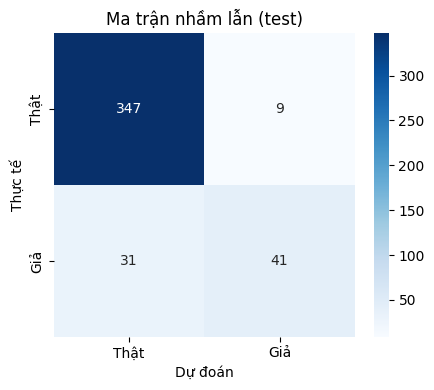

error_type
False Negative (bỏ sót tin giả)       31
False Positive (báo nhầm tin thật)     9
Name: count, dtype: int64
Độ dài TB câu sai: 188.875 | toàn test: 146.03271028037383


In [17]:
y = test["label"].values; pred = (probs_best >= 0.5).astype(int)
print(classification_report(y, pred, target_names=["Tin thật", "Tin giả"], digits=4))
cmx = confusion_matrix(y, pred)
plt.figure(figsize=(4.5, 4)); sns.heatmap(cmx, annot=True, fmt="d", cmap="Blues", xticklabels=["Thật", "Giả"], yticklabels=["Thật", "Giả"])
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Ma trận nhầm lẫn (test)"); plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=200); plt.show()

err = test.assign(prob_fake=probs_best, pred=pred)
err = err[err["pred"] != err["label"]].copy()
err["error_type"] = np.where(err["label"] == 1, "False Negative (bỏ sót tin giả)", "False Positive (báo nhầm tin thật)")
err["n_words"] = err["text"].str.split().str.len()
err["confidence"] = np.where(err["pred"] == 1, err["prob_fake"], 1 - err["prob_fake"])
err.sort_values("confidence", ascending=False)[["text", "label", "pred", "prob_fake", "error_type", "n_words"]].to_csv("results/error_samples.csv", index=False)
print(err["error_type"].value_counts()); print("Độ dài TB câu sai:", err["n_words"].mean(), "| toàn test:", test["text"].str.split().str.len().mean())

## 8. Ablation (đánh giá trên validation, seed 42)

In [18]:
abl = []
def A(name, **kw):
    m = train_eval(kw.pop("params", BEST), seed=42, eval_df=val, **kw); abl.append(dict(experiment=name, f1_macro_val=round(m["f1_macro"], 4), f1_fake_val=round(m["f1_fake"], 4))); print(abl[-1])
A("Tham chiếu: PhoBERT tối ưu (có tách từ, max_len theo BEST)")
A("A1: không tách từ", text_col="text_raw")
A("A2: max_len = 128", params={**BEST, "max_len": 128})
A("A3: dùng class weight", class_weight=True)
A("A4: đóng băng encoder", freeze_encoder=True)
A("A5: dropout = 0.1", params={**BEST, "dropout": 0.1})
pd.DataFrame(abl).to_csv("results/ablation.csv", index=False); pd.DataFrame(abl)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Fake,F1 Macro,Roc Auc
1,No log,0.260493,0.901869,0.788462,0.569444,0.661290,0.801957,0.933130
2,No log,0.258667,0.920561,0.865385,0.625000,0.725806,0.839679,0.937871
3,No log,0.340246,0.904206,0.816327,0.555556,0.661157,0.802687,0.935179


{'experiment': 'Tham chiếu: PhoBERT tối ưu (có tách từ, max_len theo BEST)', 'f1_macro_val': 0.8027, 'f1_fake_val': 0.6612}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Fake,F1 Macro,Roc Auc
1,No log,0.291816,0.890187,0.878788,0.402778,0.552381,0.744899,0.927903
2,No log,0.325253,0.911215,0.886364,0.541667,0.672414,0.810531,0.919398
3,No log,0.348075,0.911215,0.840000,0.583333,0.688525,0.818377,0.913565


{'experiment': 'A5: dropout = 0.1', 'f1_macro_val': 0.8184, 'f1_fake_val': 0.6885}


,experiment,f1_macro_val,f1_fake_val
0,"Tham chiếu: PhoBERT tối ưu (có tách từ, max_le...",0.8027,0.6612
1,A1: không tách từ,0.8114,0.6774
2,A2: max_len = 128,0.7946,0.6512
3,A3: dùng class weight,0.8367,0.7231
4,A4: đóng băng encoder,0.6074,0.2955
5,A5: dropout = 0.1,0.8184,0.6885


## 9. Gói kết quả để nộp

In [19]:
!zip -qr results.zip results && echo "Đã tạo results.zip"
from google.colab import files; files.download("results.zip")

Đã tạo results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>